# Baseline model: metadata-driven Ridge regression

This notebook trains Ridge regression on the HDB + open-MRT processed tables. Its feature contract comes entirely from `data/processed/hdb_mrt/preprocessing_metadata.json`; feature names are not duplicated in model code.

The goals are to:

1. validate the preprocessing metadata against train and test;
2. compare Ridge with a hierarchical-median reference;
3. select the Ridge penalty using expanding-window validation;
4. report RMSE, MAE, and $R^2$ on future time blocks;
5. diagnose remaining temporal and subgroup errors; and
6. produce predictions for the HDB + MRT test table.

In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.style.use("seaborn-v0_8-whitegrid")
RANDOM_STATE = 5228

# Support kernels launched from the repository root or notebooks/.
ROOT = next(
    (
        candidate for candidate in [Path.cwd(), *Path.cwd().parents]
        if (candidate / "data/processed/hdb_mrt/train_preprocessed.csv").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not locate the HDB/MRT processed datasets")

PROCESSED_DIR = ROOT / "data/processed/hdb_mrt"
TRAIN_PATH = PROCESSED_DIR / "train_preprocessed.csv"
TEST_PATH = PROCESSED_DIR / "test_preprocessed.csv"
METADATA_PATH = PROCESSED_DIR / "preprocessing_metadata.json"

In [2]:
train = pd.read_csv(TRAIN_PATH, parse_dates=["RENT_DATE"])
test = pd.read_csv(TEST_PATH, parse_dates=["RENT_DATE"])
metadata = json.loads(METADATA_PATH.read_text())

TARGET = metadata["target"]
ROW_ID = metadata["row_id"]
assert TARGET in train and TARGET not in test
assert train[ROW_ID].is_unique and test[ROW_ID].is_unique

dataset_summary = pd.DataFrame({
    "rows": [len(train), len(test)],
    "columns": [train.shape[1], test.shape[1]],
    "first_month": [train["RENT_DATE"].min(), test["RENT_DATE"].min()],
    "last_month": [train["RENT_DATE"].max(), test["RENT_DATE"].max()],
}, index=["train", "test"])
display(dataset_summary)
display(train[TARGET].describe().to_frame().T)
print(f"Loaded processed data from: {PROCESSED_DIR}")

,rows,columns,first_month,last_month
train,150000,39,2021-01-01,2025-03-01
test,50000,38,2025-03-01,2026-07-01


,count,mean,std,min,25%,50%,75%,max
MONTHLY_RENT,"150,000.000","2,719.037",749.731,300.000,"2,100.000","2,700.000","3,200.000","7,600.000"


Loaded processed data from: /Users/charlie/Desktop/course slides/CS5228/project/cs5228-group6/data/processed/hdb_mrt


## Why Ridge regression is the baseline

The EDA motivates a regularized linear benchmark:

- monthly rent is only mildly right-skewed, so raw SGD remains an interpretable target;
- property, calendar, HDB block, and MRT variables contain strong additive signals;
- several fields overlap, including flat type with floor area and lease year with derived building ages;
- one-hot encoding creates correlated sparse predictors, for which Ridge is more stable than ordinary least squares;
- Ridge provides a fast yardstick before nonlinear models such as CatBoost.

Rent changes strongly over time, so evaluation must preserve chronological order. The HDB and MRT features are constructed without the target and are applied identically to train and test.

In [3]:
# The preprocessing metadata is the single source of truth for model columns.
FEATURES = list(metadata["model_features"])
CATEGORICAL_FEATURES = list(metadata["categorical_features"])

if not FEATURES:
    raise ValueError("metadata.model_features must not be empty")
if len(FEATURES) != len(set(FEATURES)):
    raise ValueError("metadata.model_features contains duplicates")

unknown_categorical = sorted(set(CATEGORICAL_FEATURES) - set(FEATURES))
if unknown_categorical:
    raise ValueError(f"Categorical features absent from model_features: {unknown_categorical}")

categorical_set = set(CATEGORICAL_FEATURES)
NUMERIC_FEATURES = [feature for feature in FEATURES if feature not in categorical_set]

missing_train = sorted(set(FEATURES + [TARGET, "RENT_DATE"]) - set(train.columns))
missing_test = sorted(set(FEATURES + [ROW_ID, "RENT_DATE"]) - set(test.columns))
if missing_train or missing_test:
    raise ValueError(f"Missing columns; train={missing_train}, test={missing_test}")

non_numeric = [
    column for column in NUMERIC_FEATURES
    if not pd.api.types.is_numeric_dtype(train[column])
    or not pd.api.types.is_numeric_dtype(test[column])
]
if non_numeric:
    raise TypeError(f"Metadata marks non-numeric columns as numeric: {non_numeric}")

feature_audit = pd.DataFrame({
    "role": ["categorical" if feature in categorical_set else "numeric" for feature in FEATURES],
    "dtype": train[FEATURES].dtypes.astype(str),
    "missing_pct": train[FEATURES].isna().mean().mul(100),
    "n_unique": train[FEATURES].nunique(dropna=False),
})
display(feature_audit)
print(
    f"Metadata features: {len(FEATURES)} total = "
    f"{len(CATEGORICAL_FEATURES)} categorical + {len(NUMERIC_FEATURES)} numeric"
)

,role,dtype,missing_pct,n_unique
TOWN,categorical,str,0.000,26
BLOCK,categorical,str,0.000,2720
STREET,categorical,str,0.000,576
FLAT_TYPE,categorical,str,0.000,6
FLAT_MODEL,categorical,str,0.000,20
FLOOR_AREA_SQM,numeric,float64,0.000,156
LEASE_COMMENCE_DATE,numeric,int64,0.000,57
RENT_YEAR,numeric,int64,0.000,5
RENT_MONTH,numeric,int64,0.000,12
RENT_QUARTER,numeric,int64,0.000,4


Metadata features: 36 total = 12 categorical + 24 numeric


## Validation and preprocessing design

The three expanding windows follow the EDA recommendation. Every fold trains only on months earlier than its validation block.

All learned preprocessing is fit inside each fold:

- numeric missing values are median-imputed and standardized;
- categorical missing values are mode-imputed and one-hot encoded;
- categories seen fewer than 10 times are pooled by `OneHotEncoder`;
- unseen future categories use the infrequent/unknown representation.

For context, Ridge is compared with a hierarchical-median reference based on town and flat type. These target medians are recomputed using only each fold's historical data.

In [4]:
SPLITS = [
    {"fold": "2023 H2", "start": "2023-07-01", "end": "2024-01-01"},
    {"fold": "2024 H1", "start": "2024-01-01", "end": "2024-07-01"},
    {"fold": "2024 H2–2025 Q1", "start": "2024-07-01", "end": "2025-04-01"},
]

split_rows = []
for split in SPLITS:
    start, end = pd.Timestamp(split["start"]), pd.Timestamp(split["end"])
    train_mask = train["RENT_DATE"] < start
    valid_mask = train["RENT_DATE"].between(start, end, inclusive="left")
    split_rows.append({
        "fold": split["fold"],
        "train_through": start - pd.offsets.MonthBegin(1),
        "validate_from": start,
        "validate_through": end - pd.offsets.MonthBegin(1),
        "train_rows": int(train_mask.sum()),
        "validation_rows": int(valid_mask.sum()),
    })
display(pd.DataFrame(split_rows))

,fold,train_through,validate_from,validate_through,train_rows,validation_rows
0,2023 H2,2023-06-01,2023-07-01,2023-12-01,87937,17900
1,2024 H1,2023-12-01,2024-01-01,2024-06-01,105837,18179
2,2024 H2–2025 Q1,2024-06-01,2024-07-01,2025-03-01,124016,25984


In [5]:
def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(
            handle_unknown="infrequent_if_exist",
            min_frequency=10,
            sparse_output=True,
        )),
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
    ])


def regression_metrics(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


def hierarchical_median_predict(past, future):
    prediction = pd.Series(np.nan, index=future.index, dtype=float)
    pair_median = past.groupby(["TOWN", "FLAT_TYPE"])[TARGET].median()
    pair_index = pd.MultiIndex.from_frame(future[["TOWN", "FLAT_TYPE"]])
    prediction.loc[:] = pair_median.reindex(pair_index).to_numpy()
    for column in ["TOWN", "FLAT_TYPE"]:
        fallback = future[column].map(past.groupby(column)[TARGET].median())
        prediction = prediction.fillna(fallback)
    return prediction.fillna(past[TARGET].median()).to_numpy()

In [6]:
ALPHAS = [0.1, 1.0, 10.0, 100.0]
evaluation_rows = []
fold_predictions = {}

for split in SPLITS:
    start, end = pd.Timestamp(split["start"]), pd.Timestamp(split["end"])
    train_mask = train["RENT_DATE"] < start
    valid_mask = train["RENT_DATE"].between(start, end, inclusive="left")
    past, future = train.loc[train_mask], train.loc[valid_mask]

    reference_pred = hierarchical_median_predict(past, future)
    evaluation_rows.append({
        "fold": split["fold"], "model": "Hierarchical median", "alpha": np.nan,
        **regression_metrics(future[TARGET], reference_pred),
    })

    preprocessor = make_preprocessor()
    X_past = preprocessor.fit_transform(past[FEATURES])
    X_future = preprocessor.transform(future[FEATURES])

    for alpha in ALPHAS:
        ridge = Ridge(alpha=alpha, solver="lsqr", max_iter=10_000, tol=1e-4)
        ridge.fit(X_past, past[TARGET])
        ridge_pred = ridge.predict(X_future)
        fold_predictions[(split["fold"], alpha)] = ridge_pred
        evaluation_rows.append({
            "fold": split["fold"], "model": "Ridge", "alpha": alpha,
            **regression_metrics(future[TARGET], ridge_pred),
        })

results = pd.DataFrame(evaluation_rows)
alpha_summary = (
    results.query("model == 'Ridge'")
    .groupby("alpha")[["RMSE", "MAE", "R2"]]
    .mean()
    .sort_values("RMSE")
)
SELECTED_ALPHA = float(alpha_summary.index[0])

display(results.query("model == 'Ridge'").pivot(index="alpha", columns="fold", values="RMSE"))
display(alpha_summary)
print(f"Selected alpha = {SELECTED_ALPHA:g} (lowest mean expanding-window RMSE)")

fold,2023 H2,2024 H1,2024 H2–2025 Q1
alpha,,,
0.100,600.474,605.534,585.340
1.000,599.391,604.527,584.031
10.000,597.950,604.040,582.228
100.000,600.185,606.850,584.024


,RMSE,MAE,R2
alpha,,,
10.000,594.739,444.572,0.251
1.000,595.983,447.183,0.248
100.000,597.020,444.563,0.246
0.100,597.116,448.594,0.245


Selected alpha = 10 (lowest mean expanding-window RMSE)


In [7]:
selected_results = pd.concat([
    results.query("model == 'Hierarchical median'"),
    results[(results["model"] == "Ridge") & (results["alpha"] == SELECTED_ALPHA)],
]).sort_values(["fold", "model"])
display(selected_results)

mean_comparison = selected_results.groupby("model")[["RMSE", "MAE", "R2"]].mean()
display(mean_comparison)

reference_rmse = mean_comparison.loc["Hierarchical median", "RMSE"]
ridge_rmse = mean_comparison.loc["Ridge", "RMSE"]
relative_gain = 100 * (reference_rmse - ridge_rmse) / reference_rmse
print(f"Ridge reduces mean RMSE by {relative_gain:.1f}% versus the hierarchical-median reference.")
print("The declining R² across later folds is evidence of temporal distribution shift and baseline underfitting.")

,fold,model,alpha,RMSE,MAE,R2
0,2023 H2,Hierarchical median,NaN,998.323,863.992,-0.853
3,2023 H2,Ridge,10.000,597.950,461.891,0.335
5,2024 H1,Hierarchical median,NaN,878.460,770.756,-0.654
8,2024 H1,Ridge,10.000,604.040,439.672,0.218
10,2024 H2–2025 Q1,Hierarchical median,NaN,808.056,708.571,-0.540
13,2024 H2–2025 Q1,Ridge,10.000,582.228,432.154,0.201


,RMSE,MAE,R2
model,,,
Hierarchical median,894.946,781.106,-0.682
Ridge,594.739,444.572,0.251


Ridge reduces mean RMSE by 33.5% versus the hierarchical-median reference.
The declining R² across later folds is evidence of temporal distribution shift and baseline underfitting.


## Baseline result

The tables above are generated from the current metadata-defined feature set. The selected alpha is the value with the lowest mean expanding-window RMSE. Because the feature contract can change during preprocessing, result values are not hard-coded into this narrative cell.

## Error diagnostics on the latest future block

The latest validation fold is the closest available proxy for the unseen future. Residual is defined as `actual − predicted`, so positive bias means the model underpredicts. The plots check calibration, time drift, and systematic subgroup errors rather than relying on a single aggregate score.

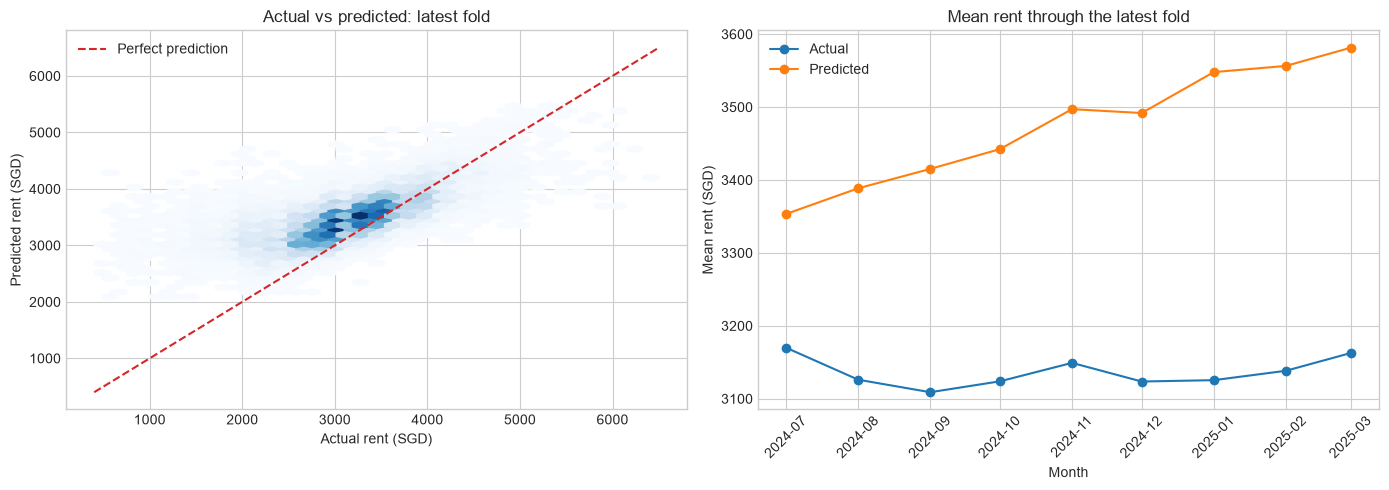

Mean residual (actual − predicted): SGD -337.7


In [8]:
latest = SPLITS[-1]
latest_mask = train["RENT_DATE"].between(
    pd.Timestamp(latest["start"]), pd.Timestamp(latest["end"]), inclusive="left"
)
latest_diagnostics = train.loc[latest_mask, ["RENT_DATE", "TOWN", "FLAT_TYPE", TARGET]].copy()
latest_diagnostics["prediction"] = fold_predictions[(latest["fold"], SELECTED_ALPHA)]
latest_diagnostics["residual"] = latest_diagnostics[TARGET] - latest_diagnostics["prediction"]
latest_diagnostics["absolute_error"] = latest_diagnostics["residual"].abs()
latest_diagnostics["squared_error"] = latest_diagnostics["residual"].pow(2)

monthly_diagnostics = latest_diagnostics.groupby("RENT_DATE").agg(
    actual=(TARGET, "mean"), prediction=("prediction", "mean")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hexbin(
    latest_diagnostics[TARGET], latest_diagnostics["prediction"],
    gridsize=35, mincnt=1, cmap="Blues"
)
limits = [latest_diagnostics[TARGET].min(), latest_diagnostics[TARGET].max()]
axes[0].plot(limits, limits, "--", color="#D62728", label="Perfect prediction")
axes[0].set(title="Actual vs predicted: latest fold", xlabel="Actual rent (SGD)", ylabel="Predicted rent (SGD)")
axes[0].legend()

axes[1].plot(monthly_diagnostics.index, monthly_diagnostics["actual"], marker="o", label="Actual")
axes[1].plot(monthly_diagnostics.index, monthly_diagnostics["prediction"], marker="o", label="Predicted")
axes[1].set(title="Mean rent through the latest fold", xlabel="Month", ylabel="Mean rent (SGD)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Mean residual (actual − predicted): SGD {latest_diagnostics['residual'].mean():,.1f}")

In [9]:
def subgroup_metrics(frame, group_column):
    return (
        frame.groupby(group_column)
        .agg(
            rows=(TARGET, "size"),
            MAE=("absolute_error", "mean"),
            RMSE=("squared_error", lambda values: np.sqrt(values.mean())),
            bias=("residual", "mean"),
        )
        .sort_values("RMSE", ascending=False)
    )

print("Latest-fold error by flat type:")
display(subgroup_metrics(latest_diagnostics, "FLAT_TYPE"))
print("Towns with the highest latest-fold RMSE (minimum 200 validation rows):")
town_errors = subgroup_metrics(latest_diagnostics, "TOWN")
display(town_errors.query("rows >= 200").head(10))

Latest-fold error by flat type:


,rows,MAE,RMSE,bias
FLAT_TYPE,,,,
2-room,708,493.682,643.076,-472.398
3-room,8562,465.297,608.514,-423.897
1-room,10,507.564,596.788,-507.564
executive,1309,423.842,589.121,-158.607
4-room,9468,416.903,570.394,-320.270
5-room,5927,402.998,552.131,-263.983


Towns with the highest latest-fold RMSE (minimum 200 validation rows):


,rows,MAE,RMSE,bias
TOWN,,,,
jurong west,1802,450.401,634.899,-250.170
kallang/whampoa,1001,464.519,631.521,-321.547
bukit merah,1501,448.437,617.957,-315.005
queenstown,1046,460.562,614.686,-341.755
woodlands,1305,443.229,604.438,-370.242
yishun,1337,441.481,597.175,-388.762
geylang,753,444.813,595.834,-341.500
toa payoh,1006,434.618,592.847,-321.594
bedok,1532,436.899,590.951,-361.955


## Interpreting the fitted baseline

The following refit uses only data before the latest validation block. Numeric coefficients correspond to a one-standard-deviation change; categorical coefficients are regularized one-hot adjustments around the intercept. Because correlated address fields can share weight, these coefficients are descriptive—not causal.

In [10]:
latest_start = pd.Timestamp(SPLITS[-1]["start"])
interpretation_train = train[train["RENT_DATE"] < latest_start]
interpretation_preprocessor = make_preprocessor()
X_interpretation = interpretation_preprocessor.fit_transform(interpretation_train[FEATURES])
interpretation_model = Ridge(
    alpha=SELECTED_ALPHA, solver="lsqr", max_iter=10_000, tol=1e-4
).fit(X_interpretation, interpretation_train[TARGET])

coefficient_table = pd.DataFrame({
    "feature": interpretation_preprocessor.get_feature_names_out(),
    "coefficient_sgd": interpretation_model.coef_,
})
display(coefficient_table.nsmallest(12, "coefficient_sgd"))
display(coefficient_table.nlargest(12, "coefficient_sgd"))

,feature,coefficient_sgd
6068,categorical__PROPERTY_KEY_queenstown|27|ghim m...,-437.141
3802,categorical__PROPERTY_KEY_bukit merah|69|redhi...,-313.247
669,categorical__BLOCK_291,-293.946
4243,categorical__PROPERTY_KEY_clementi|117|clement...,-286.665
3677,categorical__PROPERTY_KEY_bukit merah|141|jala...,-280.956
5554,categorical__PROPERTY_KEY_kallang/whampoa|8|sa...,-279.638
2812,categorical__PROPERTY_KEY_ang mo kio|330|ang m...,-277.820
6240,categorical__PROPERTY_KEY_sembawang|418|canber...,-271.674
3168,categorical__PROPERTY_KEY_bedok|55|new upper c...,-269.905
7618,categorical__PROPERTY_KEY_woodlands|753|woodla...,-269.538


,feature,coefficient_sgd
2403,categorical__STREET_lim liak street,339.011
8073,categorical__TOWN_STREET_bukit merah|lim liak ...,339.011
5008,categorical__PROPERTY_KEY_jurong west|179|yung...,332.976
6117,categorical__PROPERTY_KEY_queenstown|7|ghim mo...,309.890
8717,categorical__HDB_SUBZONE_tiong bahru,299.877
6074,categorical__PROPERTY_KEY_queenstown|29|ghim m...,285.228
2692,categorical__FLAT_MODEL_terrace,284.865
6079,categorical__PROPERTY_KEY_queenstown|30|ghim m...,284.605
4858,categorical__PROPERTY_KEY_jurong east|218|juro...,276.159
2046,categorical__BLOCK_945,275.823


## How to improve beyond the baseline

The metadata-driven Ridge model now includes the recommended HDB and open-MRT variables. Recommended next experiments are:

1. compare the same chronological folds with and without HDB/MRT features to quantify their incremental value;
2. train CatBoost on the same metadata feature contract to capture nonlinearities and time-by-location interactions;
3. test splines or piecewise trends for `MONTH_INDEX`;
4. compare native categorical handling with fold-safe encoding for high-cardinality address fields;
5. add school, mall, COE, and stock features only as separate ablations.

A feature group should be retained only if it improves future-period RMSE consistently, not because it improves a random split.

## Fit on all training data and predict the test set

After alpha selection, the complete preprocessing and Ridge pipeline is refit on all labelled rows. Predictions retain `ROW_ID` for alignment checks.

The command-line script uses the same metadata-driven feature contract and HDB/MRT files by default:

```bash
python scripts/create_ridge_submission.py
```

In [11]:
final_pipeline = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("ridge", Ridge(alpha=SELECTED_ALPHA, solver="lsqr", max_iter=10_000, tol=1e-4)),
])
final_pipeline.fit(train[FEATURES], train[TARGET])
test_prediction = final_pipeline.predict(test[FEATURES])

ridge_test_predictions = pd.DataFrame({
    ROW_ID: test[ROW_ID].to_numpy(),
    TARGET: test_prediction,
})
assert len(ridge_test_predictions) == len(test)
assert ridge_test_predictions[ROW_ID].equals(test[ROW_ID].reset_index(drop=True))
assert np.isfinite(ridge_test_predictions[TARGET]).all()

display(ridge_test_predictions.head())
display(ridge_test_predictions[TARGET].describe().to_frame().T)

,ROW_ID,MONTHLY_RENT
0,0,"3,089.390"
1,1,"3,908.689"
2,2,"3,285.890"
3,3,"3,389.005"
4,4,"3,558.933"


,count,mean,std,min,25%,50%,75%,max
MONTHLY_RENT,"50,000.000","3,629.712",428.367,"2,021.237","3,337.469","3,613.031","3,884.733","5,805.598"
